
# Euron Week 6 — 회귀(LinearRegression/다항회귀) 과제

데이터셋:
  - `fetch_california_housing()` (보스턴 데이터셋 사용 금지)
  - 합성 코사인 데이터 (문항 C에서 생성)

## 파트 구성
- **A. 경사하강법(Gradient Descent)**
- **B. LinearRegression & OLS**
- **C. 회귀 평가 지표 & Scikit-Learn Scoring API**
- **D. 다항 회귀 & 과소적합/과적합 (Bias–Variance)**

> 유의: `load_boston()`는 삭제된 데이터셋입니다. **반드시** `fetch_california_housing()`을 사용하세요.


##A.경사하강법(Gradient Descent)

간단한 회귀 구현하기

y=3x+3=5을 근사하기 위한 100개의 데이터 세트를 만들고, 경사하강법을 이용해 회귀 계수를 도출하세요


*   데이터 개수: 100개
*   실제 회귀식: y=3x+5
*   학습률:0.01
*   반복횟수: 1000회
*   평가지표: 평균 제곱 오차(MSE)

1. NumPy를 이용해 데이터를 생성
2. 비용 함수와 가중치 업데이트 함수를 구현
3. 경사하강법으로 w1, w0을 학습
4. 학습된 회귀 계수와 최종 비용 출력
5. 산점도와 회귀선을 시각화



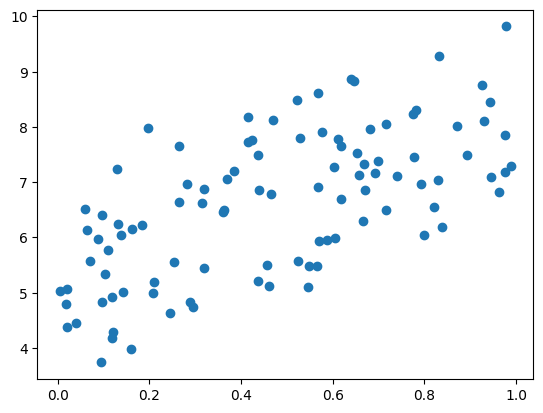

w1: 2.877
w0: 5.253
Gradient Descent Total Cost: 0.9927


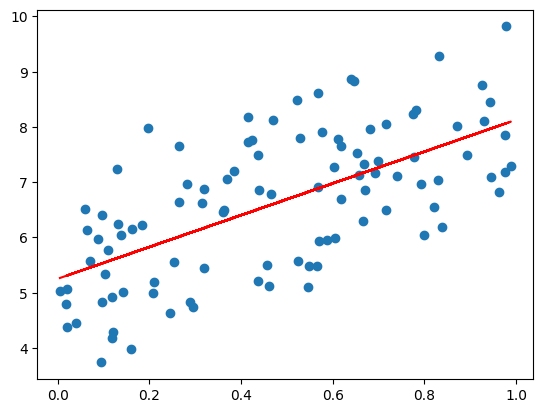

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 데이터 생성
np.random.seed(0)

X = # 답안 작성 #
y = # 답안 작성 #

plt.scatter(X, y)
plt.show()


# 2. 비용 함수
def get_cost(y, y_pred):
    N = len(y)
    cost = # 답안 작성 #
    return # 답안 작성 #


# 3. 가중치 업데이트 함수
def get_weight_updates(w1, w0, X, y, learning_rate=0.01):
    N = len(y)

    w1_update = # 답안 작성 #
    w0_update = # 답안 작성 #

    y_pred = np.dot(X, w1.T) + w0
    diff = y - y_pred

    w0_factors = np.ones((N, 1))

    w1_update = -(2 / N) * learning_rate * np.dot(X.T, diff)
    w0_update = -(2 / N) * learning_rate * np.dot(
        w0_factors.T, diff
    )

    return # 답안 작성 #

# 4. 경사하강법 반복 수행
def gradient_descent_steps(X, y, iters=# 답안 작성 #):
    w0 = np.zeros((1, 1))
    w1 = np.zeros((1, 1))

    for ind in range(iters):
        w1_update, w0_update = get_weight_updates(
            w1, w0, X, y, learning_rate=0.01
        )

        w1 = # 답안 작성 #
        w0 = # 답안 작성 #

    return # 답안 작성 #


# 5. 학습 결과 출력
w1, w0 = gradient_descent_steps(X, y, iters=# 답안 작성 #)

print("w1:", round(w1[0, 0], 3))
print("w0:", round(w0[0, 0], 3))

y_pred = w1[0, 0] * X + w0
print(
    "Gradient Descent Total Cost:",
    round(get_cost(y, y_pred), 4)
)


# 6. 회귀선 시각화
plt.scatter(X, y)
plt.plot(X, y_pred, color="red")
plt.show()


## B. LinearRegression & OLS

### 캘리포니아 주택 가격 예측 (fit_intercept 비교) — ★★
1) `fetch_california_housing()`으로 데이터셋(X, y)을 불러오고, `train_test_split(test_size=0.2, random_state=42)`로 분리하세요.  
2) `LinearRegression(fit_intercept=True)`과 `LinearRegression(fit_intercept=False)`를 각각 학습하고, 테스트 세트 **R²**를 비교하세요.  
3) 두 설정의 차이가 나는 이유를 **간단히** 서술하세요.


In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1) 데이터 로드 & 분리
data = fetch_california_housing()
X, y = data.data, data.target
# 답안 작성 #

# 2) 두 모델 학습
lr_t = LinearRegression(fit_intercept=#답안 작성#)
lr_f = LinearRegression(fit_intercept=#답안 작성#)
lr_t.fit(X_train, y_train)
lr_f.fit(X_train, y_train)

# 3) 성능 비교
#답안 작성#
print("R2 (fit_intercept=True):", r2_t)
print("R2 (fit_intercept=False):", r2_f)

R2 (fit_intercept=True): 0.5757877060324524
R2 (fit_intercept=False): 0.5196561679229004



3. 두 설정의 차이가 나는 이유를 간단히 서술하세요.


## C. 회귀 평가 지표 & Scikit-Learn Scoring API (총 2문항)

### C-1. 지표 함수 구현 & 비교 — ★★
`mean_absolute_error, mean_squared_error, r2_score`를 이용해 MAE, MSE, RMSE, R²를 구현/출력하세요.  

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_squared_log_error
import numpy as np

y_true = # 답안 작성 #
y_pred = # 답안 작성 #

mae = # 답안 작성 #
mse = # 답안 작성 #
rmse = # 답안 작성 #
r2 = # 답안 작성 #

print(mae, mse, rmse, r2)

0.533200130495698 0.5558915986952422 0.7455813830127749 0.5757877060324524



### C-2. `neg_mean_squared_error`의 의미 — ★
1) `cross_val_score(..., scoring='neg_mean_squared_error')`로 5-Fold 결과를 얻고, **실제 MSE**로 변환해 평균/표준편차를 출력하세요.  
2) 왜 `neg_` 접두사가 붙는지 한 줄로 설명하세요.


In [ ]:
from sklearn.model_selection import cross_val_score

scores = #답안 작성#
real_mse =#답안 작성#

print(#답안 작성#)

0.5582901717686811 0.06560199778303842


C-2-2. 왜 neg_ 접두사가 붙는지 한 줄로 설명하세요.


## D. 다항 회귀 & 과소적합/과적합

### 코사인 데이터: Degree 1/4/15 비교
1) 구간 `[0, 1]`에서 **30개**의 X를 임의 샘플링하고, `y = cos(2πX) + N(0, 0.1)`로 타깃을 생성하세요.  
2) `Pipeline([PolynomialFeatures(degree=d), LinearRegression()])`로 **degree=1,4,15** 모델을 학습하세요.  
3) 각 모델에 대해 **10-Fold MSE**를 구해 평균을 출력하고, **Underfitting/Good Fit/Overfitting**을 판별하세요.  


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score

rng = np.random.RandomState(0)
Xc = rng.rand(30, 1)
yc = np.cos(2*np.pi*Xc).ravel() + rng.normal(0, 0.1, size=30)

def cv_mse_for_degree(d):
    model = Pipeline([('poly', PolynomialFeatures(degree=d, include_bias=True)),
                      ('lr', LinearRegression())])
    scores = # 답안 작성 #
    return # 답안 작성 #

for d in [1,4,15]:
    print(d, cv_mse_for_degree(d))

1 0.7226999447492073
4 0.02001921890005632
15 1290.6553915093937


D-3 Underfitting/Good Fit/Overfitting을 판별하세요.